# 04 · Daily totals

Daily PV energy (kWh) against daily GTI insolation (kWh/m²) and the satellite sunshine fraction. Curtailed time lowers PV totals, so the share of unconstrained daylight readings is shown too.

In [1]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from common import load_joined, load_satellite, load_snapshots

TZ = "Europe/Kyiv"
plt.rcParams["figure.figsize"] = (13, 4)
plt.rcParams["axes.grid"] = True
STATE_COLORS = {
    "unconstrained": "tab:green",
    "curtailed": "tab:red",
    "unknown": "tab:orange",
    "dark": "lightgray",
}

In [2]:
from common import DATA_DIR

snapshots = load_snapshots().tz_convert(TZ)
satellite = load_satellite().tz_convert(TZ)
daily_sat = pd.read_csv(sorted(DATA_DIR.glob(
    "openmeteo_satellite_radiation_seamless_daily_*.csv"))[-1])
daily_sat["day"] = pd.to_datetime(daily_sat["date"].str[:10]).dt.date
daily_sat = daily_sat.set_index("day")

# Readings are ~1 minute apart: integrate power over the real gaps,
# capped at 5 minutes so outages in logging don't count as production.
gap_h = (snapshots.index.to_series().diff().dt.total_seconds()
         .clip(upper=300).fillna(60) / 3600)
pv_kwh = (snapshots["solar_power_w"] * gap_h / 1000).groupby(
    snapshots.index.date).sum()
coverage_h = gap_h.groupby(snapshots.index.date).sum()
daylight = snapshots[snapshots["state"] != "dark"]
unconstrained_share = (daylight["state"] == "unconstrained").groupby(
    daylight.index.date).mean()

gti_kwh_m2 = (satellite["global_tilted_irradiance"] / 6 / 1000).groupby(
    satellite.index.date).sum(min_count=1)
daily = pd.DataFrame({
    "pv_kwh": pv_kwh,
    "logged_h": coverage_h,
    "unconstrained_share": unconstrained_share,
    "gti_kwh_m2": gti_kwh_m2,
    "sunshine_fraction": daily_sat["sunshine_duration"]
                         / daily_sat["daylight_duration"],
}).dropna(subset=["pv_kwh"])
# First and last day are partial logs.
daily = daily[daily["logged_h"] > 23]
daily.round(2)

,pv_kwh,logged_h,unconstrained_share,gti_kwh_m2,sunshine_fraction
2026-10-26,2.32,24.0,1.00,0.84,0.01
2026-10-27,3.20,24.0,1.00,0.90,0.02
2026-10-28,3.20,24.0,0.82,0.84,0.03
2026-10-29,2.44,24.0,1.00,0.75,0.00
2026-10-30,1.82,24.0,1.00,0.83,0.00
2026-10-31,1.44,24.0,1.00,0.60,0.00
2026-11-01,2.19,24.0,1.00,0.77,0.00
2026-11-02,1.20,24.0,1.00,0.48,0.00
2026-11-03,1.50,24.0,1.00,0.51,0.00


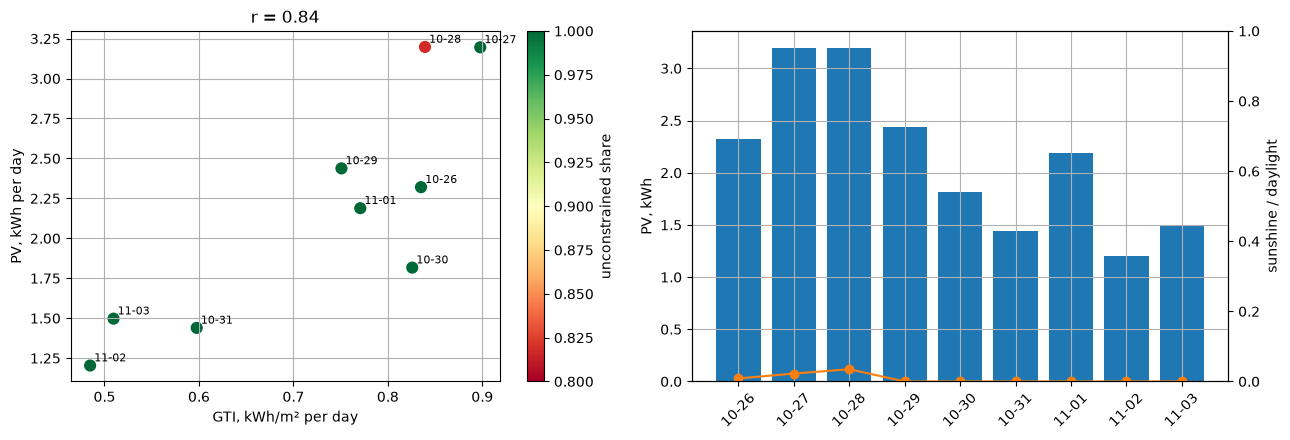

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sc = axes[0].scatter(daily["gti_kwh_m2"], daily["pv_kwh"],
                     c=daily["unconstrained_share"], cmap="RdYlGn",
                     vmin=0.8, vmax=1, s=60)
for day, row in daily.iterrows():
    axes[0].annotate(str(day)[5:], (row["gti_kwh_m2"], row["pv_kwh"]),
                     fontsize=8, xytext=(3, 3), textcoords="offset points")
fig.colorbar(sc, ax=axes[0], label="unconstrained share")
axes[0].set_xlabel("GTI, kWh/m² per day")
axes[0].set_ylabel("PV, kWh per day")
axes[0].set_title(
    f"r = {daily['pv_kwh'].corr(daily['gti_kwh_m2']):.2f}")

axes[1].bar([str(d)[5:] for d in daily.index], daily["pv_kwh"],
            label="PV kWh")
ax2 = axes[1].twinx()
ax2.plot([str(d)[5:] for d in daily.index], daily["sunshine_fraction"],
         c="tab:orange", marker="o", label="sunshine fraction")
ax2.set_ylim(0, 1)
ax2.grid(False)
axes[1].set_ylabel("PV, kWh")
ax2.set_ylabel("sunshine / daylight")
axes[1].tick_params(axis="x", rotation=45)
fig.tight_layout()